# Heart Disease Risk Prediction
## Model Experiments,Tuning and Evaluation

This notebook documents the training, comparison, hyperparameter tuning, and evaluation of machine learning models for heart disease risk prediction.

### Objectives
- Train multiple baseline classification models.
- Compare model performance using stratified cross-validation.
- Optimize promising models through hyperparameter tuning.
- Evaluate tuned models on an independent test dataset.
- Identify the leading candidate model for further analysis.

**Dataset:** UCI Heart Disease Dataset (Cleveland subset)

**Target variable:** `target` (0 = No Heart Disease, 1 = Heart Disease)

**Random State:** 42

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES AND PROJECT CONFIGURATION
# ============================================================

import sys
import json
import joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import train_test_split
import warnings

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

CURRENT_PATH = Path.cwd()
PROJECT_ROOT = next(
    (path for path in [CURRENT_PATH, *CURRENT_PATH.parents]
     if (path / "src").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing the src folder."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# Import project modules
# ------------------------------------------------------------

from src.preprocessing import build_preprocessor
from src.train import build_model_pipelines, train_models
from src.evaluate import evaluate_classifier, print_evaluation_report
from src.model_comparison import compare_models_cv
from src.tune import (
    get_parameter_grids,
    nested_cv_model_selection,
    tune_models
)

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")

print("=" * 60)
print("HEART DISEASE RISK PREDICTION")
print("MODEL EXPERIMENTS")
print("=" * 60)
print(f"\nProject Root: {PROJECT_ROOT}")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print("\nAll libraries and project modules imported successfully!")

HEART DISEASE RISK PREDICTION
MODEL EXPERIMENTS

Project Root: C:\Users\ASUS\OneDrive\Documents\GitHub\heart-disease-risk-prediction
Random State: 42
Test Size: 0.2

All libraries and project modules imported successfully!


In [2]:
# ============================================================
# 2. LOAD THE CLEANED DATASET
# ============================================================

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "heart_disease_model_input.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

from src.data_validation import validate_model_dataset

validation_report = validate_model_dataset(df)

print("DATASET VALIDATION")
display(pd.Series(validation_report))

# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

# ------------------------------------------------------------
# Dataset overview
# ------------------------------------------------------------

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"\nDataset Shape       : {df.shape}")
print(f"Number of Records   : {df.shape[0]}")
print(f"Number of Features  : {X.shape[1]}")

print("\nFeature Columns:")
print(list(X.columns))

print("\nTarget Distribution:")
print(y.value_counts().sort_index().rename(
    index={0: "No Heart Disease", 1: "Heart Disease"}
))

print("\nDataset loaded successfully!")

DATASET VALIDATION


records                               303
features                               13
missing_feature_cells                   6
target_distribution      {0: 164, 1: 139}
duplicate_rows                          0
dtype: object

DATASET OVERVIEW

Dataset Shape       : (303, 14)
Number of Records   : 303
Number of Features  : 13

Feature Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target Distribution:
target
No Heart Disease    164
Heart Disease       139
Name: count, dtype: int64

Dataset loaded successfully!


In [18]:
# ============================================================
# 3. BASELINE MODEL TRAINING
# ============================================================

# Build preprocessing pipeline
preprocessor = build_preprocessor()

# Train all six baseline models
baseline_models = train_models(
    X,
    y,
    preprocessor,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# Display training summary
# ------------------------------------------------------------

print("=" * 60)
print("BASELINE MODEL TRAINING SUMMARY")
print("=" * 60)
for model_name in baseline_models:
    print(f" [SUCCESS] {model_name}")
print("\nTotal Models Trained:", len(baseline_models))
print("\nAll baseline models trained successfully!")

BASELINE MODEL TRAINING SUMMARY
 [SUCCESS] Dummy Classifier
 [SUCCESS] Logistic Regression
 [SUCCESS] K-Nearest Neighbors
 [SUCCESS] Decision Tree
 [SUCCESS] Random Forest
 [SUCCESS] Support Vector Machine

Total Models Trained: 6

All baseline models trained successfully!


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [41]:
# ============================================================
# 4. BASELINE MODEL COMPARISON
# ============================================================

# Perform 5-fold stratified cross-validation
baseline_results = compare_models_cv(
    X,
    y,
    preprocessor,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# Display comparison results
# ------------------------------------------------------------

print("=" * 80)
print("BASELINE MODEL COMPARISON")
print("=" * 80)
display(
    baseline_results.round(4)
)

# ------------------------------------------------------------
# Save baseline comparison results
# ------------------------------------------------------------

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
baseline_results.to_csv(
    REPORTS_DIR / "model_comparison_baseline.csv",
    index=False
)
print("\nBaseline comparison results saved successfully!")

BASELINE MODEL COMPARISON


,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,AVERAGE_PRECISION Mean,AVERAGE_PRECISION Std,SPECIFICITY Mean,SPECIFICITY Std
0,Logistic Regression,0.8547,0.0542,0.8744,0.0640,0.7979,0.0812,0.8332,0.0647,0.9188,0.0232,0.9178,0.0292,0.9028,0.0495
1,Random Forest,0.8384,0.0310,0.8505,0.0612,0.7913,0.0306,0.8185,0.0289,0.9144,0.0255,0.9090,0.0381,0.8784,0.0601
2,Support Vector Machine,0.8448,0.0506,0.8501,0.0666,0.8056,0.0656,0.8261,0.0567,0.9021,0.0319,0.9036,0.0403,0.8784,0.0562
3,K-Nearest Neighbors,0.8416,0.0411,0.8399,0.0578,0.8130,0.0686,0.8243,0.0451,0.8809,0.0336,0.8528,0.0407,0.8663,0.0544
4,Decision Tree,0.7719,0.0661,0.7612,0.0912,0.7481,0.0566,0.7520,0.0609,0.7706,0.0628,0.6860,0.0754,0.7930,0.1074
5,Dummy Classifier,0.5413,0.0059,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.4587,0.0059,1.0000,0.0000



Baseline comparison results saved successfully!


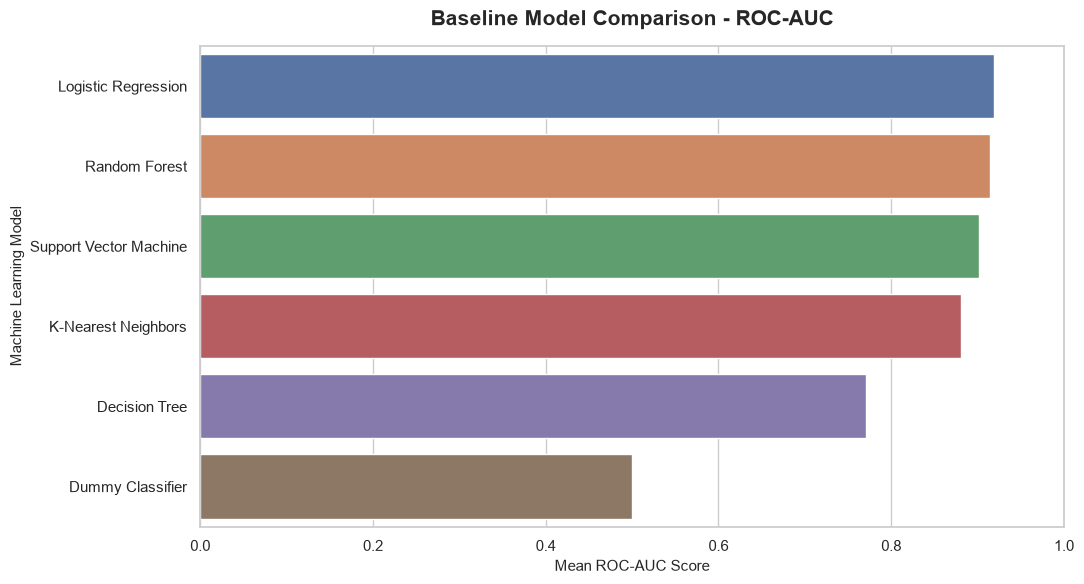

In [20]:
# ============================================================
# 6. BASELINE MODEL PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 6))
sns.barplot(
    data=baseline_results,
    x="ROC_AUC Mean",
    y="Model",
    hue="Model",
    legend=False
)
plt.title(
    "Baseline Model Comparison - ROC-AUC",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Mean ROC-AUC Score", fontsize=11)
plt.ylabel("Machine Learning Model", fontsize=11)
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / "baseline_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [21]:
# ============================================================
# 6. Nested cross-validation
# ============================================================

fold_results, oof_predictions = nested_cv_model_selection(
    X,
    y,
    preprocessor,
    random_state=RANDOM_STATE,
    outer_splits=5,
    inner_splits=4,
    n_iter=20
)


OUTER FOLD 1/5
-------------------------------------------------------
Logistic Regression: Inner ROC-AUC = 0.9078
Random Forest: Inner ROC-AUC = 0.9113


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Inner ROC-AUC = 0.8996
K-Nearest Neighbors: Inner ROC-AUC = 0.9106

Selected model: Random Forest
Outer ROC-AUC: 0.9470

OUTER FOLD 2/5
-------------------------------------------------------
Logistic Regression: Inner ROC-AUC = 0.9129
Random Forest: Inner ROC-AUC = 0.9199


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Inner ROC-AUC = 0.9107
K-Nearest Neighbors: Inner ROC-AUC = 0.9146

Selected model: Random Forest
Outer ROC-AUC: 0.8799

OUTER FOLD 3/5
-------------------------------------------------------
Logistic Regression: Inner ROC-AUC = 0.9114
Random Forest: Inner ROC-AUC = 0.9084


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Inner ROC-AUC = 0.9043
K-Nearest Neighbors: Inner ROC-AUC = 0.9000

Selected model: Logistic Regression
Outer ROC-AUC: 0.9069

OUTER FOLD 4/5
-------------------------------------------------------
Logistic Regression: Inner ROC-AUC = 0.9129
Random Forest: Inner ROC-AUC = 0.9080


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Inner ROC-AUC = 0.9088
K-Nearest Neighbors: Inner ROC-AUC = 0.8938

Selected model: Logistic Regression
Outer ROC-AUC: 0.9080

OUTER FOLD 5/5
-------------------------------------------------------
Logistic Regression: Inner ROC-AUC = 0.9165
Random Forest: Inner ROC-AUC = 0.9151


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine: Inner ROC-AUC = 0.9152
K-Nearest Neighbors: Inner ROC-AUC = 0.9081

Selected model: Logistic Regression
Outer ROC-AUC: 0.9353


In [23]:
#Nested cross-validation reu=sults

print("NESTED CROSS-VALIDATION RESULTS")

display(fold_results.round(4))

fold_results.to_csv(
    REPORTS_DIR / "nested_cv_fold_results.csv",
    index=False
)

oof_predictions.to_csv(
    REPORTS_DIR / "nested_cv_oof_predictions.csv",
    index=False
)

NESTED CROSS-VALIDATION RESULTS


,Fold,Selected Model,Inner CV ROC-AUC,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,Average Precision
0,1,Random Forest,0.9113,0.8689,0.8571,0.8571,0.8788,0.8571,0.9470,0.9473
1,2,Random Forest,0.9199,0.7869,0.7778,0.7500,0.8182,0.7636,0.8799,0.8500
2,3,Logistic Regression,0.9114,0.8361,0.8462,0.7857,0.8788,0.8148,0.9069,0.9177
3,4,Logistic Regression,0.9129,0.7833,0.7917,0.7037,0.8485,0.7451,0.9080,0.9029
4,5,Logistic Regression,0.9165,0.8667,0.9167,0.7857,0.9375,0.8462,0.9353,0.9428


In [24]:
# ============================================================
# 7. Nested CV performance summary
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1 Score",
    "ROC-AUC",
    "Average Precision"
]

nested_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        fold_results[m].mean() for m in metrics
    ],
    "Standard Deviation": [
        fold_results[m].std(ddof=1) for m in metrics
    ]
})

display(nested_summary.round(4))

nested_summary.to_csv(
    REPORTS_DIR / "nested_cv_summary.csv",
    index=False
)

print("\nModel selection frequency:")
display(
    fold_results["Selected Model"]
    .value_counts()
    .rename_axis("Model")
    .to_frame("Number of outer folds selected")
)

,Metric,Mean,Standard Deviation
0,Accuracy,0.8284,0.0416
1,Precision,0.8379,0.0557
2,Recall,0.7765,0.0563
3,Specificity,0.8723,0.0442
4,F1 Score,0.8054,0.0495
5,ROC-AUC,0.9154,0.0264
6,Average Precision,0.9121,0.0392



Model selection frequency:


,Number of outer folds selected
Model,
Logistic Regression,3
Random Forest,2


In [25]:
# ============================================================
# 8. Evaluate the selected-model procedure
# ============================================================

oof = oof_predictions.sort_values("Index")

assert len(oof) == len(X)
assert oof["Index"].nunique() == len(X)

oof_metrics = evaluate_classifier(
    oof["Actual"],
    oof["Predicted"]
)

print_evaluation_report(
    oof_metrics,
    model_name="Nested CV Model Selection Procedure"
)

print("\nClassification Report:")

print(
    classification_report(
        oof["Actual"],
        oof["Predicted"],
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)


             MODEL EVALUATION REPORT
  Model: Nested CV Model Selection Procedure
------------------------------------------------------

  PERFORMANCE METRICS

  Accuracy               : 0.8284
  Precision              : 0.8372
  Recall                 : 0.7770
  Specificity            : 0.8720
  F1 Score               : 0.8060
  ROC-AUC                : N/A
  PR-AUC                 : N/A

  CONFUSION MATRIX
  ----------------------------------
                  Predicted
                  No     Yes
  Actual No       143     21
  Actual Yes       31    108

  TN = True Negative   FP = False Positive
  FN = False Negative  TP = True Positive

             END OF EVALUATION


Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.82      0.87      0.85       164
   Heart Disease       0.84      0.78      0.81       139

        accuracy                           0.83       303
       macro avg       0.83      0.82      0.83       303

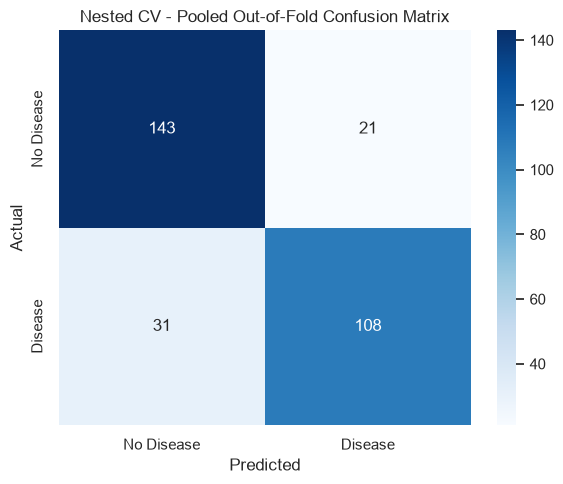

In [26]:
# ============================================================
# 9. Confusion matrix visualization
# ============================================================

cm = oof_metrics["Confusion Matrix"]

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title("Nested CV - Pooled Out-of-Fold Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "nested_cv_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

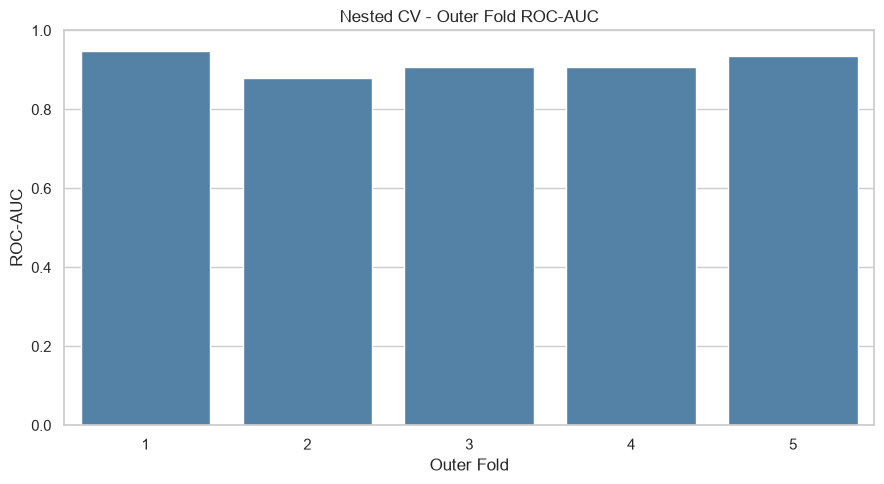

In [27]:
# ============================================================
# 10. Visualize outer-fold performance
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=fold_results,
    x="Fold",
    y="ROC-AUC",
    color="steelblue"
)

plt.ylim(0, 1)
plt.title("Nested CV - Outer Fold ROC-AUC")
plt.xlabel("Outer Fold")
plt.ylabel("ROC-AUC")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "nested_cv_fold_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

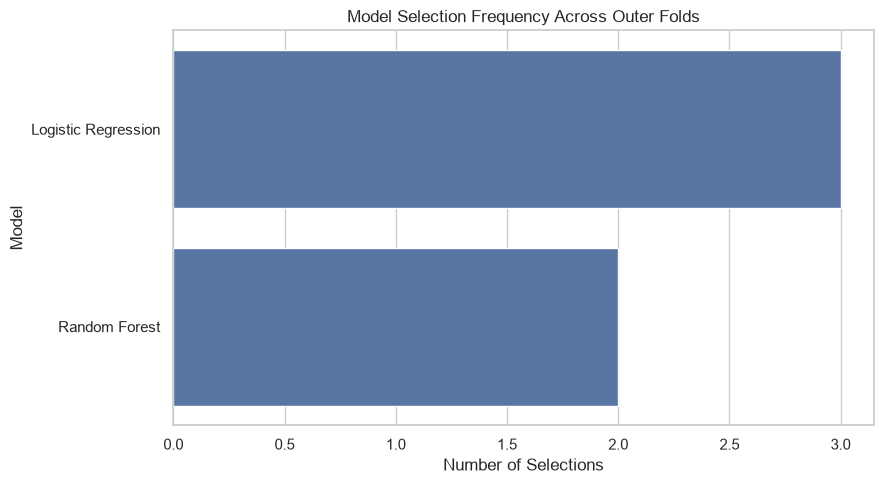

In [28]:
# Model frequency selection visualisation
selection_counts = (
    fold_results["Selected Model"]
    .value_counts()
    .reset_index()
)

selection_counts.columns = ["Model", "Selections"]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=selection_counts,
    x="Selections",
    y="Model"
)

plt.title("Model Selection Frequency Across Outer Folds")
plt.xlabel("Number of Selections")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# 11. Final model tuning
# ============================================================

candidate_pipelines = build_model_pipelines(
    preprocessor,
    random_state=RANDOM_STATE
)

parameter_grids = get_parameter_grids()

models_to_tune = {
    name: candidate_pipelines[name]
    for name in parameter_grids
}

best_models, tuning_results = tune_models(
    models=models_to_tune,
    parameter_grids=parameter_grids,
    X_train=X,
    y_train=y,
    random_state=RANDOM_STATE,
    n_iter=20,
    n_splits=5
)


Tuning: Logistic Regression
---------------------------------------------
Best ROC-AUC: 0.9210
Best Parameters: {'classifier__solver': 'lbfgs', 'classifier__class_weight': None, 'classifier__C': 0.1}

Tuning: Random Forest
---------------------------------------------
Best ROC-AUC: 0.9193
Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__class_weight': None}

Tuning: Support Vector Machine
---------------------------------------------


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best ROC-AUC: 0.9157
Best Parameters: {'classifier__kernel': 'linear', 'classifier__gamma': 'scale', 'classifier__class_weight': None, 'classifier__C': 0.1}

Tuning: K-Nearest Neighbors
---------------------------------------------
Best ROC-AUC: 0.9188
Best Parameters: {'classifier__weights': 'distance', 'classifier__p': 1, 'classifier__n_neighbors': 11}


In [30]:
# ============================================================
# 12. Tuning Report
# ============================================================

tuning_summary = pd.DataFrame([
    {
        "Model": name,
        "Best CV ROC-AUC": result["Best ROC-AUC"],
        "Best Parameters": result["Best Parameters"]
    }
    for name, result in tuning_results.items()
])

tuning_summary = tuning_summary.sort_values(
    "Best CV ROC-AUC",
    ascending=False
)

display(tuning_summary.round(4))

tuning_summary.to_csv(
    REPORTS_DIR / "final_tuning_results.csv",
    index=False
)

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.9210,"{'classifier__solver': 'lbfgs', 'classifier__c..."
1,Random Forest,0.9193,"{'classifier__n_estimators': 300, 'classifier_..."
3,K-Nearest Neighbors,0.9188,"{'classifier__weights': 'distance', 'classifie..."
2,Support Vector Machine,0.9157,"{'classifier__kernel': 'linear', 'classifier__..."


In [31]:
# ============================================================
# 13. Select and save the final model
# ============================================================

selected_model_name = tuning_summary.iloc[0]["Model"]

final_model = best_models[selected_model_name]

print("SELECTED FINAL MODEL")
print("--------------------")
print(selected_model_name)

print(
    "Best CV ROC-AUC:",
    round(
        tuning_results[selected_model_name]["Best ROC-AUC"],
        4
    )
)

print("\nSelected parameters:")

print(
    tuning_results[selected_model_name]["Best Parameters"]
)

SELECTED FINAL MODEL
--------------------
Logistic Regression
Best CV ROC-AUC: 0.921

Selected parameters:
{'classifier__solver': 'lbfgs', 'classifier__class_weight': None, 'classifier__C': 0.1}


In [33]:
#Save the entire fitted pipeline

MODELS_DIR = PROJECT_ROOT / "models"
MODEL_PATH = MODELS_DIR / "final_model.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Final model saved:")
print(MODEL_PATH)

Final model saved:
C:\Users\ASUS\OneDrive\Documents\GitHub\heart-disease-risk-prediction\models\final_model.joblib


In [34]:
# ============================================================
# 14. Save metadata
# ============================================================

metadata = {
    "model_name": selected_model_name,
    "best_cv_roc_auc": float(
        tuning_results[selected_model_name]["Best ROC-AUC"]
    ),
    "best_parameters": tuning_results[
        selected_model_name
    ]["Best Parameters"],
    "training_records": int(len(X)),
    "feature_columns": X.columns.tolist(),
    "dataset": "UCI Cleveland Heart Disease Dataset",
    "random_state": RANDOM_STATE,
    "prediction_threshold": 0.5,
    "evaluation_method": "Nested Stratified Cross-Validation",
    "outer_folds": 5,
    "inner_folds": 4
}

with open(
    MODELS_DIR / "model_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("Model metadata saved.")

Model metadata saved.


## 11. Experimental Results and Conclusion

### Baseline Model Comparison

Six machine learning classifiers were evaluated using 5-fold Stratified Cross-Validation.

Logistic Regression achieved the **highest baseline ROC-AUC** of **0.9188**, followed by Random Forest (**0.9144**) and Support Vector Machine (**0.9021**).

Logistic Regression also achieved the **highest baseline F1 score** of **0.8332** and **Average Precision** of **0.9178**, demonstrating strong overall classification performance.

### Nested Cross-Validation

Nested Stratified Cross-Validation was performed using 5 outer folds and 4 inner folds to evaluate the model-selection procedure and reduce the risk of optimistic performance estimates.

The outer-fold evaluation produced the following results:

- Mean Accuracy: **0.8284**
- Mean Precision: **0.8379**
- Mean Recall: **0.7764**
- Mean Specificity: **0.8724**
- Mean F1 Score: **0.8054**
- Mean ROC-AUC: **0.9154**
- Mean Average Precision: **0.9121**

Logistic Regression was selected in 3 out of 5 outer folds, while Random Forest was selected in the remaining 2 folds.

The results indicate that both Logistic Regression and Random Forest are competitive candidates, with Logistic Regression being selected more frequently during the nested model-selection procedure.

### Hyperparameter Tuning

Four promising models were selected for hyperparameter optimization:
- Logistic Regression
- Random Forest
- Support Vector Machine
- K-Nearest Neighbors

Logistic Regression achieved the highest tuning cross-validation ROC-AUC of **0.9210**, followed by Random Forest (0.9193), K-Nearest Neighbors (0.9188), and Support Vector Machine (0.9157).

The best Logistic Regression configuration used the LBFGS solver, a regularization parameter (C) of 0.1, and no class weighting.

### Model Selection

Logistic Regression is identified as the leading candidate based on its highest tuning cross-validation ROC-AUC of 0.9210 and its selection in 3 out of 5 outer folds during nested cross-validation.

Random Forest remains a strong alternative, having been selected in 2 outer folds and achieving the second-highest tuning ROC-AUC of 0.9193.

The relatively small differences between the leading models indicate that further evaluation and external validation would be valuable before drawing stronger conclusions about model superiority.

### Limitations

- The dataset contains only 303 records.
- The experiments are based on the Cleveland subset of the UCI Heart Disease Dataset.
- Nested cross-validation provides more reliable model-selection evaluation, but performance estimates still have uncertainty due to the limited dataset size.
- Performance may not generalize to other patient populations or healthcare settings.
- The current experiments do not establish clinical validity or diagnostic suitability.

### Conclusion

The experiments demonstrate that multiple machine learning approaches can identify patterns associated with heart disease in the selected dataset.

Logistic Regression is carried forward as the leading candidate for explainability analysis and subsequent integration into the educational prediction application, based on its baseline performance, nested cross-validation model-selection frequency, and hyperparameter tuning results.

Random Forest is retained as a strong alternative for further investigation.

The models are experimental and are not intended to replace professional medical assessment.